In [2]:
# Cell 1: A blank image as a grid of numbers

WIDTH = 20
HEIGHT = 8
WHITE = 255
BLACK = 0

grid = [[WHITE] * WIDTH for _ in range(HEIGHT)]
print(len(grid), len(grid[0]))
print(grid[0])

8 20
[255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255]


In [3]:
# Cell 2: Show the grid as text and paint one pixel
def show(grid):
    """Print the grid as text: '#' for black, '.' for white."""
    for row in grid:
        line = ""
        for pixel in row:
            line += "#" if pixel == BLACK else "."
        print(line)

grid[2][5] = BLACK
show(grid)

....................
....................
.....#..............
....................
....................
....................
....................
....................


In [4]:
# Cell 3: Draw a horizontal line
def draw_hline(grid, row, start, end):
    """Paint one row black from column start up to, but not including, end."""
    for col in range(start, end):
        grid[row][col] = BLACK

draw_hline(grid, 4, 2, 18)
show(grid)

....................
....................
.....#..............
....................
..################..
....................
....................
....................


In [5]:
# Cell 4: Draw the busbar with Pillow
from PIL import Image, ImageDraw

image = Image.new("L", (400, 200), color=WHITE)
draw = ImageDraw.Draw(image)
draw.line((40, 50, 360, 50), fill=BLACK, width=4)
print(image.size, image.getpixel((100, 50)), image.getpixel((100, 150)))
image.save("diagram_01.png")

(400, 200) 0 255


In [6]:
!ls -l diagram_01.png

-rw-r--r-- 1 root root 552 Nov  4 13:05 diagram_01.png


In [7]:
# Cell 5: Confirm Colab gave us a GPU
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [8]:
# Cell 6: Install zstd (unpacking) and pciutils + lshw (GPU detection)
!apt-get install -y -q zstd pciutils lshw

Reading package lists...
Building dependency tree...
Reading state information...
zstd is already the newest version (1.5.5+dfsg2-2build1.1).
pciutils is already the newest version (1:3.10.0-2build1).
lshw is already the newest version (02.19.git.2021.06.19.996aaad9c7-2ubuntu0.24.04.1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


In [9]:
# Cell 7: Install Ollama
!curl -fsSL https://ollama.com/install.sh | sh

>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> NVIDIA GPU installed.
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [10]:
# Cell 8: Start the Ollama server in the background
!nohup ollama serve > ollama.log 2>&1 &
!sleep 8

In [11]:
# Cell 9: Install the Ollama Python client
!pip install -q ollama

In [12]:
# Cell 10: Download the chat model
import ollama

print(ollama.pull("gemma4:e2b").status)

success


In [13]:
# Cell 11: Ask a vision model about the diagram
VISION_MODEL = "gemma4:e2b"

response = ollama.chat(
    model=VISION_MODEL,
    messages=[
        {
            "role": "user",
            "content": "Describe this drawing in one sentence.",
            "images": ["diagram_01.png"],
        },
    ],
    think=False,
)
print(response.message.content)

This is a simple, thick, horizontal black line on a white background.


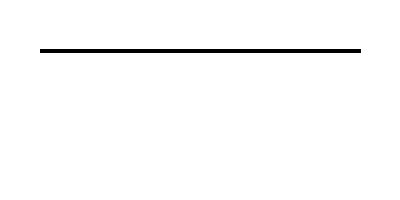

In [14]:
# Cell 5: Display the diagram
display(image)

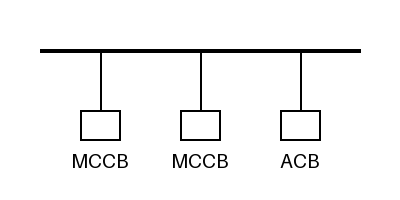

In [ ]:
# Cell 6: Add breakers and labels (answer key: 2 MCCB, 1 ACB)
from PIL import ImageFont

font = ImageFont.load_default(size=20)
PARTS = [(100, "MCCB"), (200, "MCCB"), (300, "ACB")]
for x, label in PARTS:
    draw.line((x, 50, x, 110), fill=BLACK, width=2)
    draw.rectangle((x - 20, 110, x + 20, 140), outline=BLACK, width=2)
    draw.text((x, 160), label, fill=BLACK, font=font, anchor="mm")
image.save("diagram_01.png")
display(image)

In [16]:
# Cell 13: Ask a vision model to list the parts in the diagram
VISION_MODEL = "gemma4:e2b"
QUESTION = "List every part label in this drawing and how many each."

response = ollama.chat(
    model=VISION_MODEL,
    messages=[
        {
            "role": "user",
            "content": QUESTION,
            "images": ["diagram_01.png"],
        },
    ],
    think=False,
)

print(response.message.content)

Here is a list of the labels in the drawing and the count for each:

1. **MCCB:** 2
2. **ACB:** 1

**Total Labels:** 3


In [17]:
# Cell 14: Extract part counts from the free-text reply by hand
import re

PATTERN = r"(MCCB|ACB)\W+(\d+)"
print(re.findall(PATTERN, response.message.content))
print(re.findall(PATTERN, "I see two MCCBs and one ACB."))

[('MCCB', '2'), ('ACB', '1')]
[]


In [19]:
# Cell 15: Typed form for a drawing reading
from pydantic import BaseModel

class PartCount(BaseModel):
    part: str
    count: int

class DrawingReading(BaseModel):
    parts: list[PartCount]

reading = DrawingReading.model_validate_json('{"parts": [{"part": "MCCB", "count": 2}]}')
print(reading)
print(reading.parts[0].count + 1)

parts=[PartCount(part='MCCB', count=2)]
3


In [20]:
# Cell 16: Ask for a reading that fits the DrawingReading form
response = ollama.chat(
    model=VISION_MODEL,
    messages=[{"role": "user", "content": QUESTION, "images": ["diagram_01.png"]}],
    format=DrawingReading.model_json_schema(),
    think=False,
)
print(response.message.content)
reading = DrawingReading.model_validate_json(response.message.content)
print(reading)

{"parts": [
  {"part": "MCCB", "count": 1},
  {"part": "MCCB", "count": 1},
  {"part": "ACB", "count": 1}
]}
parts=[PartCount(part='MCCB', count=1), PartCount(part='MCCB', count=1), PartCount(part='ACB', count=1)]


In [21]:
# Cell 17: Total each part and compare with the answer key
ANSWER_KEY = {"MCCB": 2, "ACB": 1}

totals = {}
for row in reading.parts:
    totals[row.part] = totals.get(row.part, 0) + row.count
print(totals)
print("Match:", totals == ANSWER_KEY)

{'MCCB': 2, 'ACB': 1}
Match: True


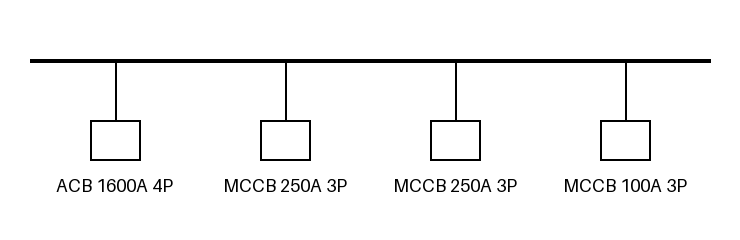

In [22]:
# Cell 18: Draw a switchboard from a list of breaker labels
font = ImageFont.load_default(size=18)

def draw_board(labels, filename):
    """Draw a busbar with one breaker per label, save it as PNG and return the image."""
    width = 170 * len(labels) + 60
    image = Image.new("L", (width, 240), color=WHITE)
    draw = ImageDraw.Draw(image)
    draw.line((30, 60, width - 30, 60), fill=BLACK, width=4)
    for i, label in enumerate(labels):
        x = 115 + 170 * i
        draw.line((x, 60, x, 120), fill=BLACK, width=2)
        draw.rectangle((x - 25, 120, x + 25, 160), outline=BLACK, width=2)
        draw.text((x, 185), label, fill=BLACK, font=font, anchor="mm")
    image.save(filename)
    return image

board_01 = ["ACB 1600A 4P", "MCCB 250A 3P", "MCCB 250A 3P", "MCCB 100A 3P"]
display(draw_board(board_01, "board_01.png"))